 ## The Physics of Formula 1: From Classical Mechanics to Computational Vehicle Dynamics         
 PHYS3211 Final Project
 
 Mar 23 2026
 
 Hongyi Ding

# Introduction

Formula 1 cars operate at the limits of mechanical and aerodynamic performance, where small changes in design parameters can significantly affect speed and stability. At high speeds, the motion of the car is governed not only by engine power, but also by aerodynamic forces and tire-road interactions, which together determine the vehicle’s performance limits.

In this project, the motion of a racing car is modeled using Newton’s second law, where the net force acting on the vehicle is expressed as the combination of several physical components:

$$
\vec{F}_{\text{net}}
=
\vec{F}_{\text{drive}}
+
\vec{F}_{\text{drag}}
+
\vec{F}_{\text{downforce}}
+
\vec{F}_{\text{friction}}
+
\vec{F}_{\text{brake}}
$$

Each term in this equation represents a key aspect of vehicle dynamics. The driving force provides propulsion, while aerodynamic drag opposes motion and grows rapidly with speed. Tire forces, which depend on friction and normal load, limit both acceleration and cornering performance, and braking forces dissipate kinetic energy to reduce speed.

This formulation provides a unified framework for analyzing how different physical effects interact to determine the maximum achievable speed of the car. By decomposing the net force into these components, this project aims to investigate how design parameters such as aerodynamic coefficients and friction influence overall vehicle performance. Due to the velocity-dependent nature of aerodynamic forces, the system exhibits nonlinear behavior, leading to a fundamental trade-off between drag and downforce.

# Physics Theory

## Longitudinal Dynamics

In this section, the car is modeled as a point mass moving only along the longitudinal direction of the track. The goal is to study how propulsion, aerodynamic drag, and rolling resistance determine the time evolution of the vehicle speed and its maximum achievable speed.

The longitudinal equation of motion is written as

$$
m\frac{dv}{dt} = F_{\text{drive}} - F_{\text{drag}} - F_{\text{roll}}.
$$

Here, $m$ is the total mass of the car including the driver, $v$ is the longitudinal speed, $F_{\text{drive}}$ is the forward driving force generated by the power unit, $F_{\text{drag}}$ is the aerodynamic drag force, and $F_{\text{roll}}$ is the rolling resistance.

The aerodynamic drag is modeled by

$$
F_{\text{drag}} = \frac{1}{2}\rho C_d A v^2,
$$

where $\rho$ is the air density, $C_d$ is the drag coefficient, and $A$ is the frontal area of the car.

Rolling resistance is approximated as

$$
F_{\text{roll}} = C_{rr} m g,
$$

where $C_{rr}$ is the rolling resistance coefficient and $g$ is gravitational acceleration.

To connect the engine power to the forward driving force, I use the relation

$$
P = F_{\text{drive}} v.
$$

Therefore, for a power-limited car, the driving force can be written as

$$
F_{\text{drive}} = \frac{P}{v}.
$$

Substituting this into the equation of motion gives

$$
m\frac{dv}{dt} = \frac{P}{v} - \frac{1}{2}\rho C_d A v^2 - C_{rr}mg.
$$

This is a nonlinear ordinary differential equation because the drag term scales as $v^2$ and the driving force scales as $1/v$. The competition between these terms determines the acceleration profile and the terminal speed of the car.

#### Numerical Method

The longitudinal speed is obtained by solving the nonlinear ordinary differential equation numerically. Let

$$
\frac{dv}{dt} = f(v),
$$

where

$$
f(v) = \frac{1}{m}\left(\frac{P}{v} - \frac{1}{2}\rho C_d A v^2 - C_{rr}mg\right).
$$

Because this equation does not have a simple closed-form solution for the full transient motion, I solve it using the fourth-order Runge-Kutta (RK4) method.

For a time step $\Delta t$, the RK4 update is

$$
k_1 = f(v_n),
$$

$$
k_2 = f\left(v_n + \frac{\Delta t}{2}k_1\right),
$$

$$
k_3 = f\left(v_n + \frac{\Delta t}{2}k_2\right),
$$

$$
k_4 = f\left(v_n + \Delta t\,k_3\right),
$$

and the next velocity is computed as

$$
v_{n+1} = v_n + \frac{\Delta t}{6}(k_1 + 2k_2 + 2k_3 + k_4).
$$

This method is chosen because it provides significantly better accuracy and stability than the forward Euler method, especially for nonlinear problems where the acceleration changes rapidly with speed.

Estimated top speed (low-drag setup, Cd=0.5): 419.0 km/h
Estimated top speed (high-downforce setup, Cd=1.0): 334.4 km/h


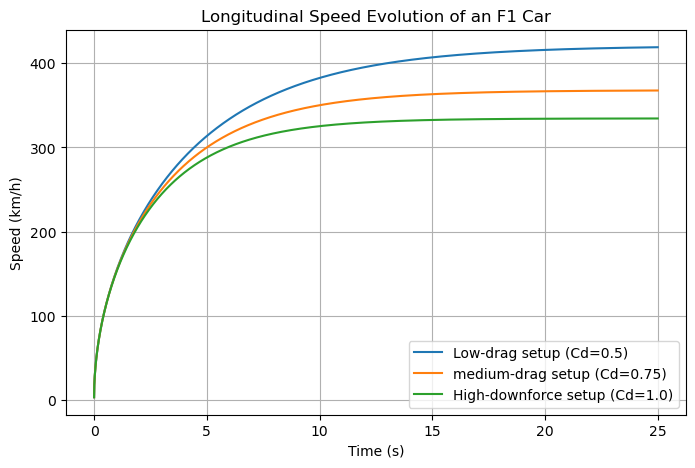

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
m = 798.0                  # kg
P = 750000.0               # W
rho = 1.225                # kg/m^3
A = 1.5                    # m^2
Crr = 0.018
g = 9.81                   # m/s^2

Cd_low = 0.5
Cd_medium = 0.75
Cd_high = 1.00


# Longitudinal acceleration model
def dvdt(v, Cd):
    v_eff = max(v, 1.0)  # avoid singularity at v = 0
    F_drive = P / v_eff
    F_drag = 0.5 * rho * Cd * A * v_eff**2
    F_roll = Crr * m * g
    return (F_drive - F_drag - F_roll) / m

# RK4 integrator
def rk4_step(v, dt, Cd):
    k1 = dvdt(v, Cd)
    k2 = dvdt(v + 0.5 * dt * k1, Cd)
    k3 = dvdt(v + 0.5 * dt * k2, Cd)
    k4 = dvdt(v + dt * k3, Cd)
    return v + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

# Simulation
def simulate_speed(Cd, t_max=25.0, dt=0.01, v0=1.0):
    n_steps = int(t_max / dt) + 1
    t = np.linspace(0, t_max, n_steps)
    v = np.zeros(n_steps)
    v[0] = v0

    for i in range(n_steps - 1):
        v[i + 1] = rk4_step(v[i], dt, Cd)

    return t, v

t_low, v_low = simulate_speed(Cd_low)
t_medium, v_medium = simulate_speed(Cd_medium)
t_high, v_high = simulate_speed(Cd_high)

# Convert to km/h
v_low_kmh = v_low * 3.6
v_medium_kmh = v_medium * 3.6
v_high_kmh = v_high * 3.6

# Estimate top speeds from final values
top_speed_low = v_low_kmh[-1]
top_speed_medium = v_medium_kmh[-1]
top_speed_high = v_high_kmh[-1]

print(f"Estimated top speed (low-drag setup, Cd={Cd_low}): {top_speed_low:.1f} km/h")
print(f"Estimated top speed (high-downforce setup, Cd={Cd_high}): {top_speed_high:.1f} km/h")

# Plot
plt.figure(figsize=(8,5))
plt.plot(t_low, v_low_kmh, label=f"Low-drag setup (Cd={Cd_low})")
plt.plot(t_medium, v_medium_kmh, label=f"medium-drag setup (Cd={Cd_medium})")
plt.plot(t_high, v_high_kmh, label=f"High-downforce setup (Cd={Cd_high})")
plt.xlabel("Time (s)")
plt.ylabel("Speed (km/h)")
plt.title("Longitudinal Speed Evolution of an F1 Car")
plt.grid(True)
plt.legend()
plt.show()

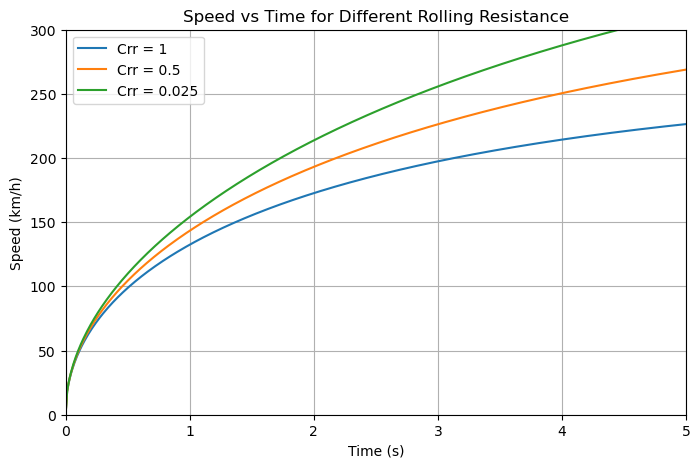

In [9]:
# Plot speed vs time
Crr_values = [1, 0.5, 0.025]

plt.figure(figsize=(8,5))

for crr in Crr_values:
    t, v, a = simulate_with_Crr(Cd_low, crr)
    plt.plot(t, v * 3.6, label=f"Crr = {crr}")  

plt.xlim(0, 5)   
plt.ylim(0, 300)

plt.xlabel("Time (s)")
plt.ylabel("Speed (km/h)")
plt.title("Speed vs Time for Different Rolling Resistance")
plt.grid(True)
plt.legend()
plt.show()

#### Discussion

The numerical results show that the low-drag setup reaches a higher terminal speed than the high-downforce setup. This is expected from the drag law

$$
F_{\text{drag}} = \frac{1}{2}\rho C_d A v^2,
$$

since a larger drag coefficient increases the resistive force at high speed. The difference becomes more significant as the speed rises because aerodynamic drag grows quadratically with velocity.

At lower speeds, the car accelerates rapidly because the power-limited driving force $P/v$ is still relatively large. As the speed increases, the available driving force decreases while drag rises strongly, causing the acceleration to approach zero. The terminal speed is reached when

$$
F_{\text{drive}} = F_{\text{drag}} + F_{\text{roll}}.
$$

And, also, during the investigation, I recognized one thing that rolling resistance has a relatively small effect on vehicle acceleration compared to aerodynamic drag. While it contributes a constant resistive force, its influence is negligible at both very low speeds (where engine power dominates) and high speeds (where aerodynamic drag dominates). Therefore, rolling resistance is not a limiting factor for maximum speed in Formula 1 cars.

This balance condition explains why top speed is limited even for a very powerful Formula 1 car.

## Lateral Dynamics

In contrast to longitudinal motion, lateral dynamics describe the behavior of the car while it is turning. In this case, the vehicle must generate sufficient lateral force to follow a curved path rather than continue in a straight line. This requirement sets a fundamental limit on the maximum cornering speed of the car.

For a car of mass $m$ moving with speed $v$ around a turn of radius $r$, the required centripetal force is

$$
F_{\text{lat}} = \frac{mv^2}{r}.
$$

This lateral force must be supplied by the tire-road interaction. In the simplest model, the maximum available tire force is limited by friction:

$$
F_{\max} = \mu N,
$$

where $\mu$ is the tire-road friction coefficient and $N$ is the normal force acting on the tires.

If only gravity is considered, then the normal force is approximately

$$
N = mg.
$$

In that simplified case, the cornering condition becomes

$$
\frac{mv^2}{r} \leq \mu mg.
$$

After canceling the mass, this gives the familiar estimate for the maximum cornering speed,

$$
v_{\max} = \sqrt{\mu g r}.
$$

However, this model is not sufficient for Formula 1 cars, because aerodynamic downforce plays a major role at high speed. Downforce increases the normal force on the tires and therefore increases the maximum frictional force available for cornering. The aerodynamic downforce is modeled as

$$
F_L = \frac{1}{2}\rho C_L A v^2,
$$

where $\rho$ is the air density, $C_L$ is the downforce coefficient, and $A$ is the effective reference area.

Including this effect, the normal force becomes

$$
N = mg + F_L.
$$

Therefore, the friction limit is modified to

$$
F_{\max} = \mu \left(mg + F_L\right).
$$

Substituting the downforce expression gives

$$
F_{\max} = \mu \left(mg + \frac{1}{2}\rho C_L A v^2\right).
$$

The lateral force required for cornering must remain below this limit, so the cornering condition becomes

$$
\frac{mv^2}{r} \leq \mu \left(mg + \frac{1}{2}\rho C_L A v^2\right).
$$

This equation captures the essential physics of high-speed cornering in Formula 1. At low speed, gravity dominates the normal load, and the maximum cornering speed behaves similarly to that of an ordinary road car. At high speed, the $v^2$ dependence of aerodynamic downforce significantly increases the available grip, allowing Formula 1 cars to sustain much larger lateral accelerations.

An important feature of this model is that it is nonlinear, since the downforce depends on the square of the speed. As a result, the available tire grip is no longer constant, but increases with velocity. This is one of the main reasons why Formula 1 cars become especially effective in fast corners.

In this section, lateral dynamics are analyzed using this force-balance framework to study how tire friction, turn radius, and aerodynamic downforce together determine the cornering performance of the car.

#### Numerical Method

In the lateral dynamics analysis, the primary objective is to determine the maximum cornering speed rather than simulate the time evolution of motion. Therefore, instead of solving a time-dependent differential equation, I use the force-balance condition directly.

The maximum cornering speed is obtained from

$$
\frac{mv^2}{r} = \mu \left(mg + \frac{1}{2}\rho C_L A v^2\right).
$$

This equation is nonlinear in $v$ due to the velocity-dependent downforce term. By rearranging the equation, the maximum allowable speed can be expressed as

$$
v_{\max} =
\sqrt{
\frac{\mu mg}
{\frac{m}{r} - \frac{1}{2}\mu \rho C_L A}
}.
$$

To study how different physical parameters influence the performance, I perform a parameter sweep over key variables such as the downforce coefficient $C_L$ and the friction coefficient $\mu$. This allows for a systematic analysis of how aerodynamic design and tire properties affect the maximum cornering speed.

This approach is computationally efficient and directly aligned with the objective of identifying conditions that maximize vehicle speed.

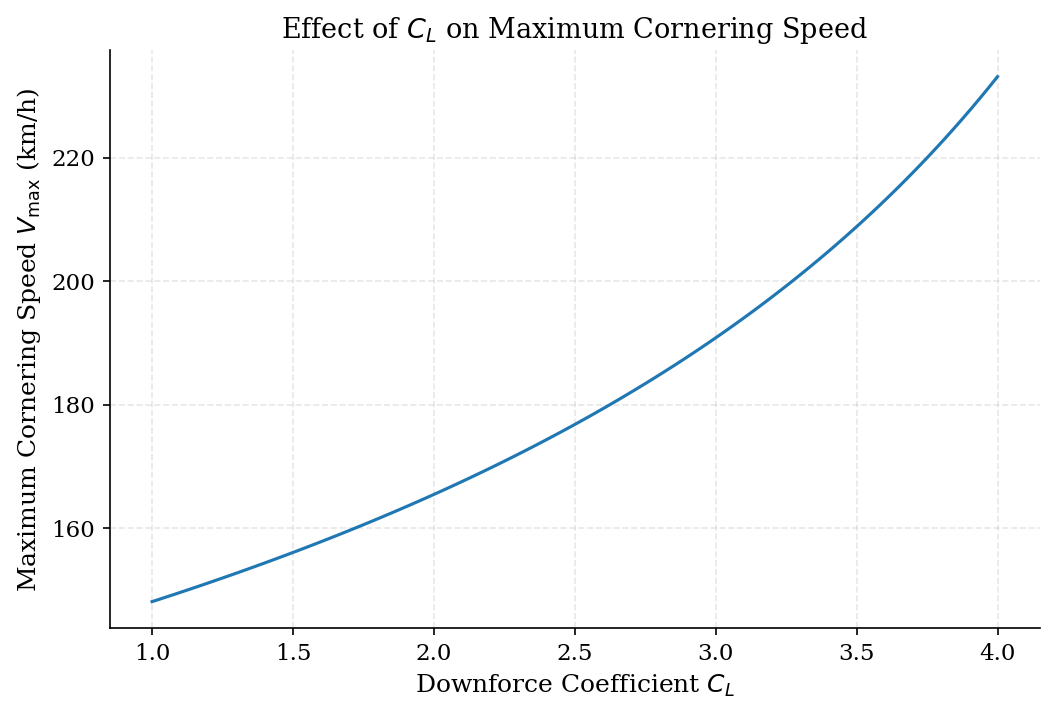

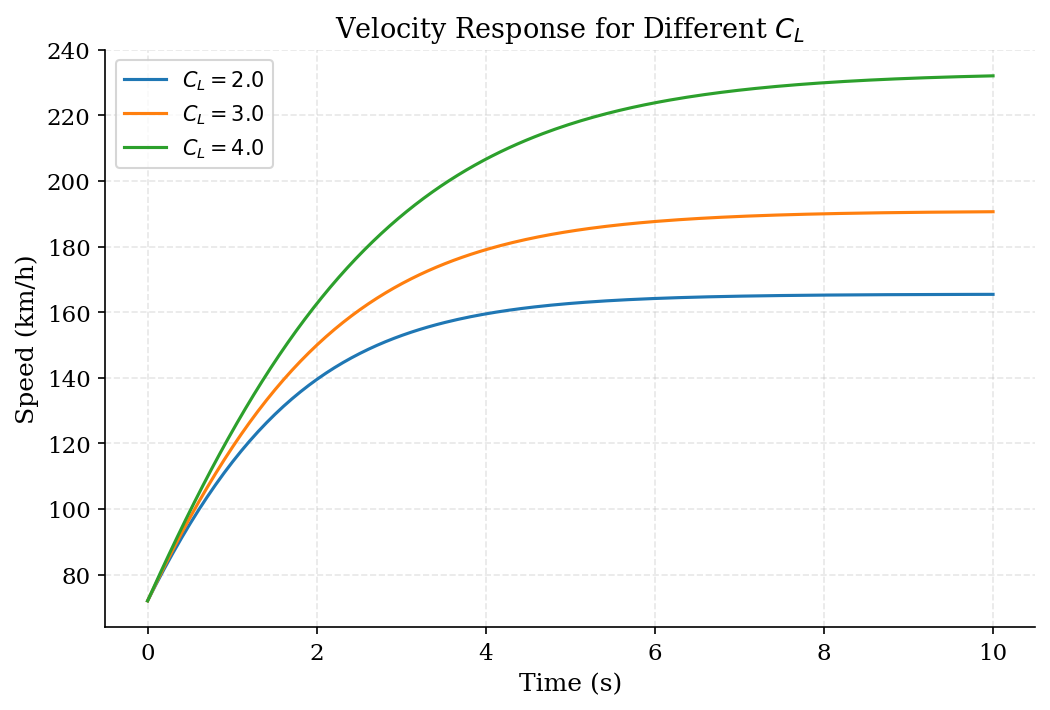

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
m = 798.0
rho = 1.225
A = 1.5
CL_default = 3.0
mu_default = 1.8
g = 9.81
r = 80.0   # turn radius (m)

dt = 0.05
t_max = 10
t = np.linspace(0, t_max, int(t_max / dt))
v0 = 20.0  # initial speed (m/s)

# Lateral acceleration model
def lateral_acc(v, CL_value, mu_value):
    F_required = m * v**2 / r
    F_L = 0.5 * rho * CL_value * A * v**2
    F_max = mu_value * (m * g + F_L)
    return (F_max - F_required) / m

# RK4 method
def rk4_step(v, dt, CL_value, mu_value):
    k1 = lateral_acc(v, CL_value, mu_value)
    k2 = lateral_acc(v + 0.5 * dt * k1, CL_value, mu_value)
    k3 = lateral_acc(v + 0.5 * dt * k2, CL_value, mu_value)
    k4 = lateral_acc(v + dt * k3, CL_value, mu_value)
    return v + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

def simulate_rk4(v0, dt, t_max, CL_value, mu_value):
    n = int(t_max / dt)
    v = np.zeros(n)
    v[0] = v0

    for i in range(n - 1):
        v[i + 1] = rk4_step(v[i], dt, CL_value, mu_value)
        if v[i + 1] < 0:
            v[i + 1] = 0.0

    return v


# Maximum cornering speed
def vmax_corner(CL_value, mu_value):
    denom = (m / r) - 0.5 * mu_value * rho * CL_value * A
    if denom <= 0:
        return np.nan
    return np.sqrt((mu_value * m * g) / denom)

# Plot 1: CL vs Vmax
CL_values = np.linspace(1.0, 4.0, 100)
vmax_CL = np.array([vmax_corner(cl, mu_default) for cl in CL_values]) * 3.6

plt.figure(figsize=(8, 5))
plt.plot(CL_values, vmax_CL)
plt.xlabel(r"Downforce Coefficient $C_L$")
plt.ylabel(r"Maximum Cornering Speed $V_{\max}$ (km/h)")
plt.title(r"Effect of $C_L$ on Maximum Cornering Speed")
plt.grid(True)
plt.show()

# Plot 2:velocity vs time for different CL
CL_compare = [2.0, 3.0, 4.0]

plt.figure(figsize=(8, 5))
for cl in CL_compare:
    v_rk4 = simulate_rk4(v0, dt, t_max, CL_value=cl, mu_value=mu_default)
    plt.plot(t, v_rk4 * 3.6, label=fr"$C_L={cl}$")

plt.xlabel("Time (s)")
plt.ylabel("Speed (km/h)")
plt.title(r"Velocity Response for Different $C_L$")
plt.legend()
plt.grid(True)
plt.show()

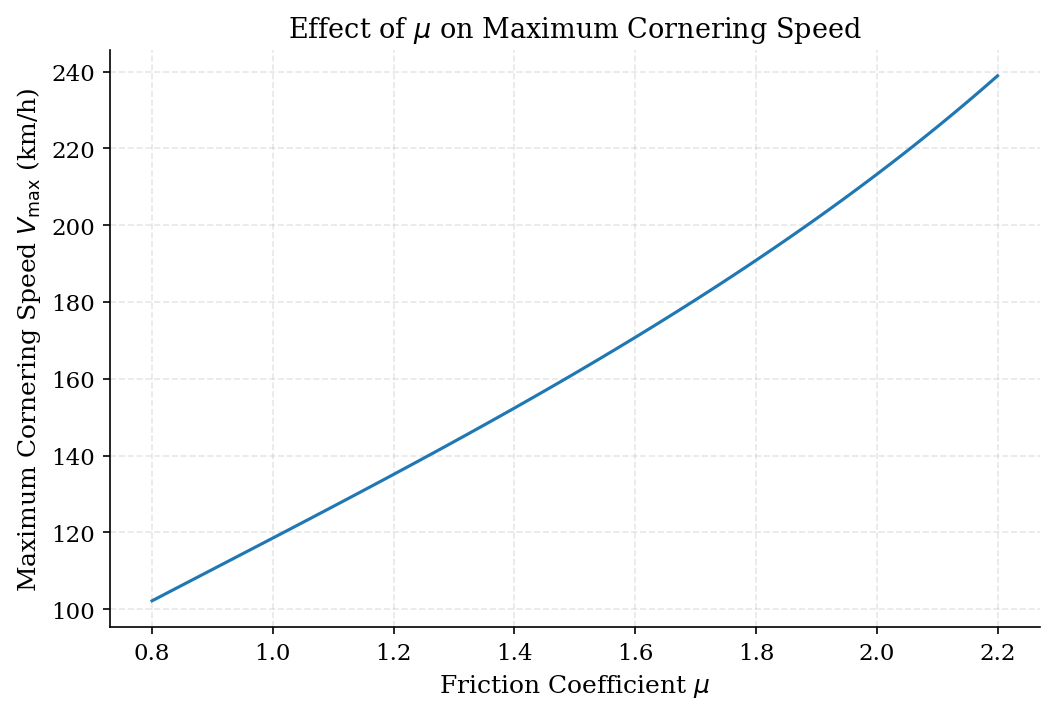

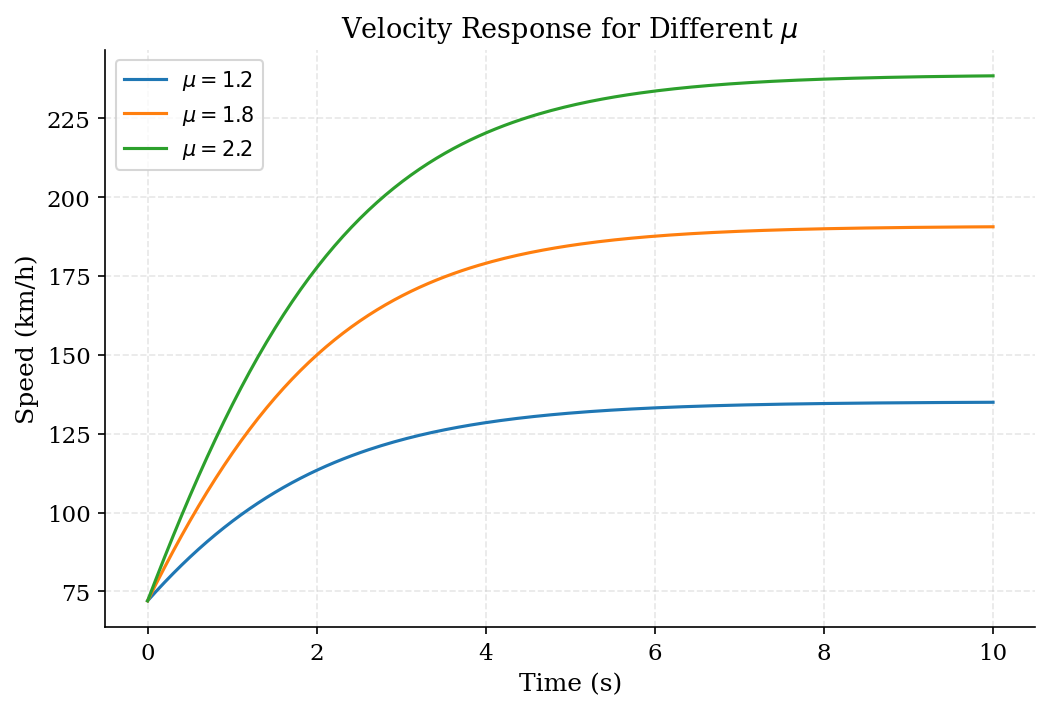

In [32]:
# Plot 3: mu vs Vmax
mu_values = np.linspace(0.8, 2.2, 100)
vmax_mu = np.array([vmax_corner(CL_default, mu_val) for mu_val in mu_values]) * 3.6

plt.figure(figsize=(8, 5))
plt.plot(mu_values, vmax_mu)
plt.xlabel(r"Friction Coefficient $\mu$")
plt.ylabel(r"Maximum Cornering Speed $V_{\max}$ (km/h)")
plt.title(r"Effect of $\mu$ on Maximum Cornering Speed")
plt.grid(True)
plt.show()

# Plot 4:velocity vs time for different mu
mu_compare = [1.2, 1.8, 2.2]

plt.figure(figsize=(8, 5))
for mu_val in mu_compare:
    v_rk4 = simulate_rk4(v0, dt, t_max, CL_value=CL_default, mu_value=mu_val)
    plt.plot(t, v_rk4 * 3.6, label=fr"$\mu={mu_val}$")

plt.xlabel("Time (s)")
plt.ylabel("Speed (km/h)")
plt.title(r"Velocity Response for Different $\mu$")
plt.legend()
plt.grid(True)
plt.show()

#### Discussion

The $C_L$ versus $V_{\max}$ plot shows that increasing the downforce coefficient increases the maximum cornering speed. This is because stronger aerodynamic downforce raises the normal force on the tires, thereby increasing the available frictional force.

The corresponding RK4 results show that larger values of $C_L$ lead to higher velocity curves throughout the simulation, indicating that the car can sustain a higher speed under the same cornering conditions.

A similar trend appears in the $\mu$ analysis. Increasing the tire-road friction coefficient improves the available grip and directly increases the maximum cornering speed. The RK4 comparison also shows that larger values of $\mu$ allow the vehicle to maintain a higher speed over time.

Together, these results demonstrate that both aerodynamic design and tire performance strongly influence the cornering speed limit of a Formula 1 car.

## Aerodynamic Components and Their Role in Vehicle Dynamics
The longitudinal and lateral dynamics analyzed in the previous sections depend on two key aerodynamic parameters: the drag coefficient $C_d$ and the downforce coefficient $C_L$. These parameters are not fixed, but are determined by the design of various aerodynamic components on the car.

In this section, I will discuss how key components influence these coefficients and thereby affect both straight-line speed and cornering performance.

#### Front Wing

The front wing generates downforce at the front of the car and plays a critical role in shaping the airflow around the vehicle. By directing air toward downstream components, it improves the overall aerodynamic efficiency.

An increase in front wing effectiveness leads to a higher downforce coefficient $C_L$, improving cornering performance. However, it also contributes to an increase in the drag coefficient $C_d$, reducing top speed in the longitudinal direction.

#### Rear Wing

The rear wing is one of the primary sources of aerodynamic downforce. It allows the car to maintain stability and achieve higher speeds in corners.

However, the rear wing also produces significant aerodynamic drag. Increasing the rear wing angle increases $C_L$ but also increases $C_d$, making it a key factor in the trade-off between straight-line speed and cornering performance.

#### Ground Effect

Ground effect refers to the generation of downforce through the acceleration of airflow underneath the car. By shaping the floor, the airflow speed increases, reducing pressure and creating a strong downward force.

Unlike wings, ground effect generates downforce with relatively low drag. This means it increases $C_L$ without significantly increasing $C_d$, making it one of the most efficient ways to improve cornering performance while maintaining high straight-line speed.

In the context of this model, ground effect effectively increases the normal force in the lateral dynamics equation, allowing for higher maximum cornering speed.

#### Drag Reduction System (DRS)

The Drag Reduction System (DRS) is a mechanism used in Formula 1 to temporarily reduce aerodynamic drag. It works by opening a flap on the rear wing, which reduces the airflow resistance.

In terms of the aerodynamic model, activating DRS reduces both the drag coefficient $C_d$ and the downforce coefficient $C_L$. The reduction in $C_d$ decreases the aerodynamic drag force, allowing the car to achieve higher acceleration and greater top speed in the longitudinal direction.

However, the reduction in $C_L$ also decreases the downforce, reducing tire grip and limiting cornering performance. For this reason, DRS can only be used in straight-line sections of the track, where lateral forces are minimal.

#### The Navier–Stokes Equations

The motion of air around a Formula 1 car is governed by the conservation of mass and momentum.

For an incompressible fluid, conservation of mass gives

$$
\nabla \cdot \mathbf{u} = 0,
$$

where $\mathbf{u}$ is the fluid velocity field.

Conservation of momentum applies Newton’s second law to a fluid element. The rate of change of momentum is balanced by pressure forces and viscous forces, giving

$$
\rho \left(
\frac{\partial \mathbf{u}}{\partial t}
+
\mathbf{u}\cdot\nabla \mathbf{u}
\right)
=
-\nabla p
+
\mu \nabla^2 \mathbf{u},
$$

where $\rho$ is the fluid density, $p$ is the pressure, and $\mu$ is the dynamic viscosity.

Dividing by $\rho$ gives the incompressible Navier–Stokes equation:

$$
\frac{\partial \mathbf{u}}{\partial t}
+
\mathbf{u}\cdot\nabla \mathbf{u}
=
-\frac{1}{\rho}\nabla p
+
\nu \nabla^2 \mathbf{u},
$$

where $\nu=\mu/\rho$ is the kinematic viscosity.

Solving the Navier–Stokes equations gives the velocity and pressure fields around the car. These fields determine the stress acting on the car surface.

The total aerodynamic force is obtained by integrating pressure and viscous stress over the body surface:

$$
\mathbf{F}
=
\int_S \left(
- p \mathbf{n}
+
\boldsymbol{\tau}\cdot\mathbf{n}
\right)\, dS,
$$

where $S$ is the car surface, $\mathbf{n}$ is the outward normal vector, and $\boldsymbol{\tau}$ is the viscous stress tensor.

This total force can be decomposed into a drag component $D$, acting opposite to the direction of motion, and a lift component $L$, acting perpendicular to the flow. In Formula 1, negative lift is called downforce.

The drag coefficient and downforce coefficient are defined by

$$
C_D = \frac{D}{\tfrac12 \rho U^2 A},
$$

$$
C_L = \frac{L}{\tfrac12 \rho U^2 A},
$$

where $U$ is a reference speed and $A$ is a reference area.

Because the Navier–Stokes equations generally do not have closed-form solutions for realistic aerodynamic geometries, numerical methods must be used. In CFD, one of the most common methods is the finite volume method (FVM).

The computational domain is divided into many small control volumes (cells). Instead of solving the equations in continuous form, the conservation laws are enforced on each cell.

For a general conserved quantity $\phi$, the integral conservation form is

$$
\frac{d}{dt}\int_V \phi\, dV
+
\int_{\partial V} \mathbf{F}_\phi \cdot \mathbf{n}\, dS
=
\int_V S_\phi\, dV,
$$

where $V$ is a control volume, $\mathbf{F}_\phi$ is the flux of $\phi$, and $S_\phi$ is a source term.

After discretization, this becomes a balance over each cell:

$$
\frac{d}{dt}(\phi_P V_P)
+
\sum_f (\mathbf{F}_{\phi,f}\cdot \mathbf{n}_f) A_f
=
S_{\phi,P} V_P,
$$

where the sum is taken over the faces of the control volume.
In this way, the PDE is converted into a coupled set of algebraic equations for the unknown values at each cell.

Simulation running... Please wait.


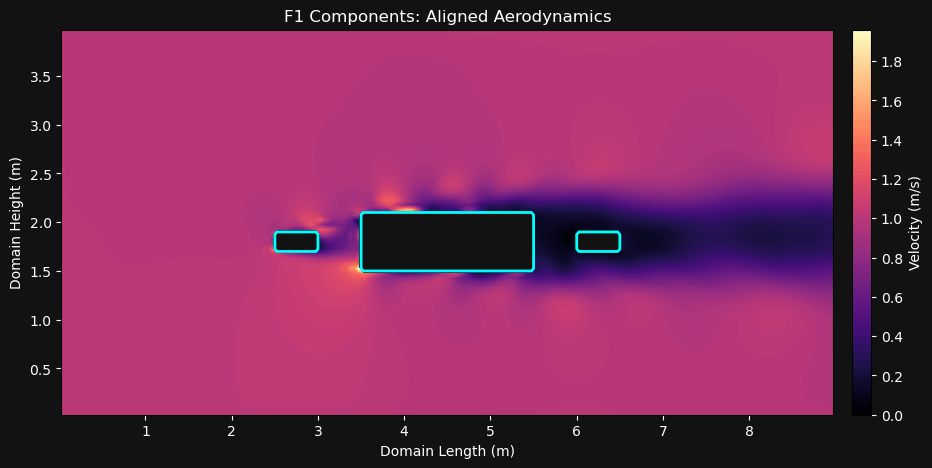

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from numba import njit, prange


# SIMULATION CONFIGURATION
@dataclass
class SimConfig:
    Nx: int = 180           
    Ny: int = 80
    Lx: float = 9.0
    Ly: float = 4.0

    rho: float = 1.2
    U_inf: float = 1.0
    nu: float = 4e-3        
    dt: float = 4e-3
    n_steps: int = 3000     

    poisson_max_iter: int = 200
    poisson_tol: float = 1e-6
    omega: float = 1.7

# UPDATED GEOMETRY: HORIZONTAL ALIGNMENT
def build_grids(cfg: SimConfig):
    dx, dy = cfg.Lx / cfg.Nx, cfg.Ly / cfg.Ny
    x_p = (np.arange(cfg.Nx) + 0.5) * dx
    y_p = (np.arange(cfg.Ny) + 0.5) * dy
    Xp, Yp = np.meshgrid(x_p, y_p)
    Xu, Yu = np.meshgrid(np.arange(cfg.Nx + 1) * dx, y_p)
    Xv, Yv = np.meshgrid(x_p, np.arange(cfg.Ny + 1) * dy)
    return dx, dy, Xp, Yp, Xu, Yu, Xv, Yv

def f1_geometry_mask(X, Y):
    # Main Body (Center)
    body = (X > 3.5) & (X < 5.5) & (Y > 1.5) & (Y < 2.1)
    
    # Front Wing 
    front_wing = (X > 2.5) & (X < 3.0) & (Y > 1.7) & (Y < 1.9)
    
    # Rear Wing 
    rear_wing = (X > 6.0) & (X < 6.5) & (Y > 1.7) & (Y < 1.9)
    
    return body | front_wing | rear_wing

# COMPUTATIONAL KERNELS (NUMBA)
@njit(parallel=True)
def momentum_step(u, v, u_star, v_star, dt, nu, dx, dy, obs_u, obs_v):
    Ny, Nx_u = u.shape
    _, Nx_v = v.shape
    for j in prange(1, Ny - 1):
        for i in range(1, Nx_u - 1):
            if obs_u[j, i]:
                u_star[j, i] = 0.0; continue
            u_conv = (u[j, i+1]**2 - u[j, i-1]**2) / (2*dx) + \
                     (0.25*(u[j,i]+u[j+1,i])*(v[j+1,i-1]+v[j+1,i]) - 0.25*(u[j,i]+u[j-1,i])*(v[j,i-1]+v[j,i])) / dy
            u_diff = nu * ((u[j, i+1] - 2*u[j, i] + u[j, i-1])/dx**2 + (u[j+1, i] - 2*u[j, i] + u[j-1, i])/dy**2)
            u_star[j, i] = u[j, i] + dt * (-u_conv + u_diff)

    for j in prange(1, Ny):
        for i in range(1, Nx_v - 1):
            if obs_v[j, i]:
                v_star[j, i] = 0.0; continue
            v_conv = (0.25*(u[j-1,i+1]+u[j,i+1])*(v[j,i]+v[j,i+1]) - 0.25*(u[j-1,i]+u[j,i])*(v[j,i]+v[j,i-1])) / dx + \
                     (v[j+1, i]**2 - v[j-1, i]**2) / (2*dy)
            v_diff = nu * ((v[j, i+1] - 2*v[j, i] + v[j, i-1])/dx**2 + (v[j+1, i] - 2*v[j, i] + v[j-1, i])/dy**2)
            v_star[j, i] = v[j, i] + dt * (-v_conv + v_diff)

@njit
def pressure_solve(p, u_star, v_star, rho, dt, dx, dy, obs_p, max_iter, omega, tol):
    Ny, Nx = p.shape
    rhs = np.zeros((Ny, Nx))
    for j in range(Ny):
        for i in range(Nx):
            rhs[j, i] = (rho/dt) * ((u_star[j, i+1] - u_star[j, i])/dx + (v_star[j+1, i] - v_star[j, i])/dy)
    
    for it in range(max_iter):
        old_p = p.copy()
        for j in range(1, Ny - 1):
            for i in range(1, Nx - 1):
                if obs_p[j, i]: continue
                p_new = ((p[j,i+1]+p[j,i-1])*dy**2 + (p[j+1,i]+p[j-1,i])*dx**2 - rhs[j,i]*dx**2*dy**2) / (2*(dx**2 + dy**2))
                p[j, i] = p[j, i] + omega * (p_new - p[j, i])
        p[:, 0] = p[:, 1]; p[:, -1] = 0.0; p[0, :] = p[1, :]; p[-1, :] = p[-2, :]
        if np.max(np.abs(p - old_p)) < tol: break

# SIMULATION EXECUTION
def main():
    cfg = SimConfig()
    dx, dy, Xp, Yp, Xu, Yu, Xv, Yv = build_grids(cfg)
    obs_p, obs_u, obs_v = f1_geometry_mask(Xp, Yp), f1_geometry_mask(Xu, Yu), f1_geometry_mask(Xv, Yv)
    
    u = np.ones((cfg.Ny, cfg.Nx + 1)) * cfg.U_inf
    v = np.zeros((cfg.Ny + 1, cfg.Nx))
    p = np.zeros((cfg.Ny, cfg.Nx))
    u_star, v_star = u.copy(), v.copy()

    print("Simulation running... Please wait.")
    for _ in range(cfg.n_steps):
        momentum_step(u, v, u_star, v_star, cfg.dt, cfg.nu, dx, dy, obs_u, obs_v)
        u_star[:, 0] = cfg.U_inf; u_star[:, -1] = u_star[:, -2] 
        pressure_solve(p, u_star, v_star, cfg.rho, cfg.dt, dx, dy, obs_p, cfg.poisson_max_iter, cfg.omega, cfg.poisson_tol)
        u[:, 1:-1] = u_star[:, 1:-1] - (cfg.dt/cfg.rho) * (p[:, 1:] - p[:, :-1])/dx
        v[1:-1, :] = v_star[1:-1, :] - (cfg.dt/cfg.rho) * (p[1:, :] - p[:-1, :])/dy
        u[obs_u], v[obs_v] = 0.0, 0.0
        u[:, 0] = cfg.U_inf; u[:, -1] = u[:, -2]

    # Visualization
    u_cc = 0.5 * (u[:, :-1] + u[:, 1:])
    v_cc = 0.5 * (v[:-1, :] + v[1:, :])
    speed = np.sqrt(u_cc**2 + v_cc**2)
    speed_masked = np.ma.masked_where(obs_p, speed)

    plt.figure(figsize=(12, 5), facecolor='#121212')
    plt.contourf(Xp, Yp, speed_masked, levels=100, cmap='magma')
    cb = plt.colorbar(pad=0.02)
    cb.set_label('Velocity of air(m/s)', color='white')
    cb.ax.yaxis.set_tick_params(color='white', labelcolor='white')
    
    plt.contour(Xp, Yp, obs_p.astype(float), levels=[0.5], colors='cyan', linewidths=2)
    plt.title("F1 Components: Aligned Aerodynamics", color='white')
    plt.xlabel("Domain Length (m)", color='white')
    plt.ylabel("Domain Height (m)", color='white')
    plt.gca().set_facecolor('#121212')
    plt.tick_params(colors='white')
    plt.show()

if __name__ == "__main__":
    main()

## Performance Trade-off and Optimization
The overall performance of a Formula 1 car is determined by a balance between straight-line speed and cornering capability. In straight-line motion, minimizing aerodynamic drag is essential for achieving high top speed, while during cornering, maximizing downforce increases tire grip and allows for higher cornering speeds.

However, these objectives are inherently in conflict. Increasing the downforce coefficient $C_L$ improves cornering performance, but also increases the drag coefficient $C_d$, reducing top speed. Therefore, the design of a Formula 1 car can be formulated as an optimization problem, where the goal is to balance these competing effects to achieve optimal overall performance.

#### Mathematical Formulation

The maximum straight-line speed is determined by the balance between driving power and aerodynamic drag:

$$
\frac{\eta P}{v} = \frac{1}{2} \rho C_d A v^2
$$

which leads to

$$
V_{\text{top}} = \left(\frac{2 \eta P}{\rho C_d A}\right)^{1/3}
$$

where $\eta$ represents drivetrain efficiency.

The maximum cornering speed is determined by the balance between centripetal force and tire grip:

$$
\frac{mv^2}{r} = \mu \left(mg + \frac{1}{2}\rho C_L A v^2\right)
$$

which gives

$$
V_{\text{corner}} =
\sqrt{
\frac{\mu m g}
{\frac{m}{r} - \frac{1}{2}\mu \rho C_L A}
}
$$

To model the aerodynamic trade-off, the drag coefficient is assumed to depend linearly on the downforce coefficient:

$$
C_d = C_{d0} + k C_L
$$

where $C_{d0}$ is the baseline drag coefficient and $k$ represents the aerodynamic coupling between drag and downforce. This relation reflects the fact that aerodynamic elements that generate downforce also introduce additional drag.

#### Performance Metric

To evaluate the overall performance of the car, a simplified lap-time-based metric is introduced. The lap time is approximated as the sum of time spent in straight-line motion and cornering:

$$
T_{\text{lap}} = \frac{L_s}{V_{\text{top}}} + \frac{n L_c}{V_{\text{corner}}}
$$

where $L_s$ is the total straight-line distance, $L_c$ is the characteristic corner length, and $n$ is the number of corners.

The optimal aerodynamic configuration is obtained by minimizing $T_{\text{lap}}$ with respect to $C_L$. This formulation directly corresponds to the numerical simulation, where different values of $C_L$ are tested and the resulting lap time is computed.

#### Aerodynamic Efficiency

To further characterize aerodynamic performance, the efficiency is defined as:

$$
\text{Efficiency} = \frac{C_L}{C_d}
$$

This quantity measures how effectively the car generates downforce relative to drag. A higher value indicates a more efficient aerodynamic design.

However, maximizing efficiency alone does not guarantee optimal performance. As shown in the simulation, the minimum lap time occurs at a specific value of $C_L$, reflecting a balance between drag and downforce rather than the maximization of either quantity individually.

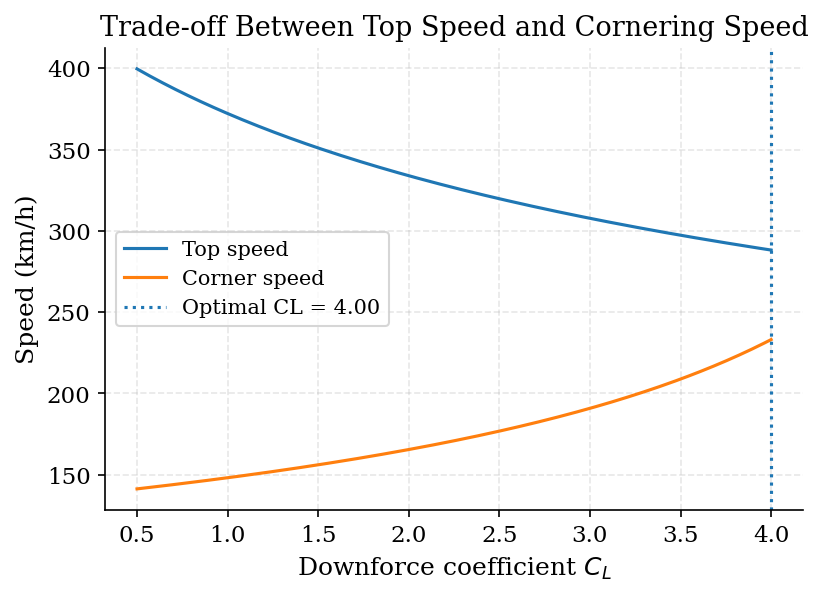

In [33]:
import numpy as np
import matplotlib.pyplot as plt

# PARAMETERS
m    = 798.0      # Mass
rho  = 1.225      # Air density 
A    = 1.5        # Reference area 
mu_t = 1.8        # Tyre friction coefficient 
g    = 9.81       # Gravity 
r    = 80.0       # Representative corner radius 
P    = 750_000.0  # Maximum power 
eta  = 0.88       # Drivetrain efficiency 

Cd0  = 0.40       # Baseline drag coefficient
k    = 0.25       # Drag-downforce coupling coefficient 

# Simplified track model
L_straight = 600.0   # total straight distance per lap 
L_corner   = 200.0   # corner arc length per corner 
n_corners  = 12      # number of corners

# 2. PHYSICS FUNCTIONS
def Cd_total(CL):
    """Total drag coefficient."""
    return Cd0 + k * CL

def top_speed(CL):
    """
    Maximum straight-line speed from power-drag balance:
        eta*P / v = 0.5*rho*Cd*A*v^2
    """
    Cd = Cd_total(CL)
    return (2 * eta * P / (rho * Cd * A)) ** (1 / 3)

def corner_speed(CL):
    """
    Maximum cornering speed from:
        m*v^2/r = mu_t * (m*g + 0.5*rho*CL*A*v^2)

    Rearranged:
        v^2 * (m/r - 0.5*mu_t*rho*CL*A) = mu_t*m*g
    """
    denom = (m / r) - 0.5 * mu_t * rho * CL * A

    if denom <= 0:
        return np.nan

    return np.sqrt((mu_t * m * g) / denom)

def lap_time_proxy(CL, Ls=L_straight, Lc=L_corner, n=n_corners):
    """
    Simplified lap-time metric.
    Lower is better.
    """
    vt = top_speed(CL)
    vc = corner_speed(CL)

    if np.isnan(vc):
        return np.nan

    t_straight = Ls / vt
    t_corner = (n * Lc) / vc
    return t_straight + t_corner

# SWEEP OVER CL
CL_values = np.linspace(0.5, 4.0, 200)

V_top = np.array([top_speed(CL) for CL in CL_values])          # m/s
V_corner = np.array([corner_speed(CL) for CL in CL_values])    # m/s
lap_time = np.array([lap_time_proxy(CL) for CL in CL_values])  # s
efficiency = np.array([aero_efficiency(CL) for CL in CL_values])
Cd_values = np.array([Cd_total(CL) for CL in CL_values])

# Convert speeds to km/h for plotting
V_top_kmh = V_top * 3.6
V_corner_kmh = V_corner * 3.6

# Optimal CL from minimum lap time
opt_idx = np.nanargmin(lap_time)
CL_opt = CL_values[opt_idx]
lap_opt = lap_time[opt_idx]
Vtop_opt = V_top_kmh[opt_idx]
Vcorner_opt = V_corner_kmh[opt_idx]
Cd_opt = Cd_values[opt_idx]
eff_opt = efficiency[opt_idx]

#TOP SPEED VS CORNER SPEED
plt.figure(figsize=(6, 4))
plt.plot(CL_values, V_top_kmh, label="Top speed")
plt.plot(CL_values, V_corner_kmh, label="Corner speed")
plt.axvline(CL_opt, linestyle=":", label=f"Optimal CL = {CL_opt:.2f}")
plt.xlabel("Downforce coefficient $C_L$")
plt.ylabel("Speed (km/h)")
plt.title("Trade-off Between Top Speed and Cornering Speed")
plt.grid(True)
plt.legend()
plt.show()

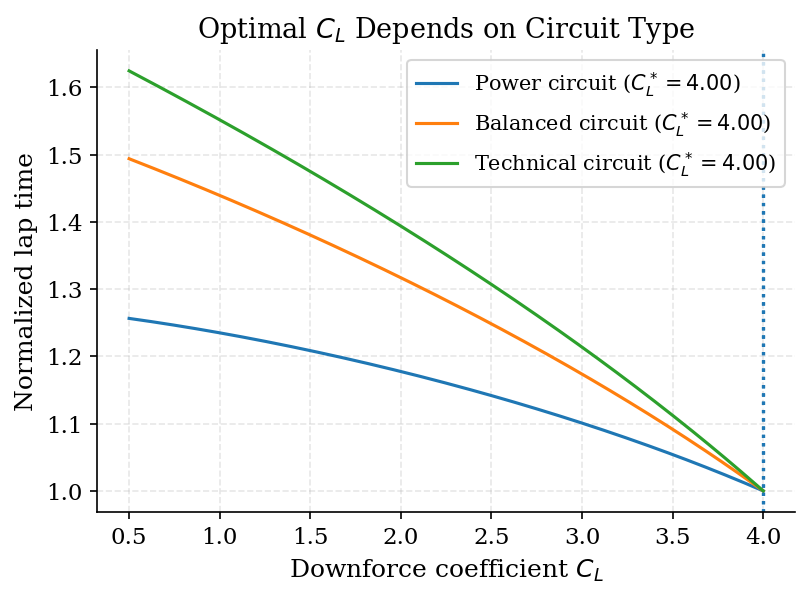

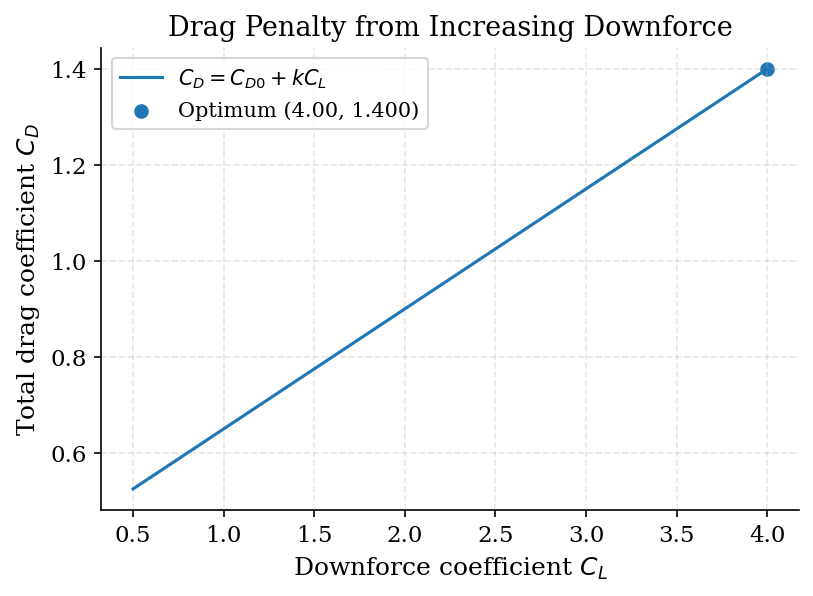

In [34]:
# CIRCUIT COMPARISON
circuits = {
    "Power circuit":   {"Ls": 1000.0, "Lc": 100.0, "n": 11},
    "Balanced circuit": {"Ls": 600.0,  "Lc": 200.0, "n": 12},
    "Technical circuit": {"Ls": 200.0, "Lc": 300.0, "n": 19},
}

plt.figure(figsize=(6, 4))

for name, params in circuits.items():
    lt = np.array([
        lap_time_proxy(CL, Ls=params["Ls"], Lc=params["Lc"], n=params["n"])
        for CL in CL_values
    ])
    lt_norm = lt / np.nanmin(lt)
    idx = np.nanargmin(lt)
    plt.plot(CL_values, lt_norm, label=f"{name} ($C_L^*={CL_values[idx]:.2f}$)")
    plt.axvline(CL_values[idx], linestyle=":")

plt.xlabel("Downforce coefficient $C_L$")
plt.ylabel("Normalized lap time")
plt.title("Optimal $C_L$ Depends on Circuit Type")
plt.grid(True)
plt.legend()
plt.show()

# DRAG PENALTY CURVE
plt.figure(figsize=(6, 4))
plt.plot(CL_values, Cd_values, label=r"$C_D = C_{D0} + k C_L$")
plt.scatter([CL_opt], [Cd_opt], label=f"Optimum ({CL_opt:.2f}, {Cd_opt:.3f})")
plt.xlabel("Downforce coefficient $C_L$")
plt.ylabel("Total drag coefficient $C_D$")
plt.title("Drag Penalty from Increasing Downforce")
plt.grid(True)
plt.legend()
plt.show()

#### Discussion

The first figure illustrates the fundamental trade-off between straight-line speed and cornering performance. As the downforce coefficient $C_L$ increases, the cornering speed increases due to the additional aerodynamic load on the tires. At the same time, the top speed decreases because the drag coefficient $C_d$ increases according to the assumed linear relation. This confirms that improving cornering performance comes at the cost of reduced straight-line speed.

To evaluate the combined effect of these competing factors, a simplified lap-time model is introduced. The second figure shows the normalized lap time for different circuit types as a function of $C_L$. In all cases, increasing $C_L$ reduces lap time, and the optimal value is located at the upper bound of the tested range. This indicates that, under the current parameter choices, the benefit of increased cornering speed dominates over the penalty in straight-line speed.

The comparison between circuits highlights how track characteristics influence performance sensitivity. Technical circuits, which contain many corners, show the strongest dependence on $C_L$, as cornering performance plays a dominant role. In contrast, power circuits, with longer straights, are less sensitive to changes in $C_L$, since straight-line speed contributes more significantly to lap time.

The third figure illustrates the drag penalty associated with increasing downforce. The linear relationship between $C_L$ and $C_d$ shows that higher downforce inevitably leads to higher aerodynamic resistance. However, within the tested range, this penalty is not sufficient to offset the gains in cornering performance.

Overall, the results demonstrate that aerodynamic design can be understood as an optimization problem, but the location of the optimum depends strongly on the modeling assumptions and parameter choices. To obtain optimized performance, the team should make a choice based on the circuit, but in most cases, the corning condition $C_L$ obviously has a better effect on lap time reduction compared to $C_d$.

# Reference
1. J. Bhalsakle and S. Deshmukh, “Aerodynamics in Formula 1: A Literature Review on Design Strategies, Performance, and Regulatory Evolutions,” Asian Journal of Convergence in Technology 11, 81–90 (2026). https://doi.org/10.33130/AJCT.2025v1103.011
2. B. Beckman, The Physics of Racing (No Bucks Racing Club, Burbank, CA, 1991)
3. F. Christ, A. Wischniewski, A. Heilmeier, and B. Lohmann, “Time-optimal trajectory planning for a race car considering variable tyre-road friction coefficients,” Vehicle System Dynamics 59, 588–612 (2021). https://doi.org/10.1080/00423114.2019.1704804
4. Dictionary, F. 1. (2026). Slip Angle: How Tyres Generate Lateral Grip. Formula 1 Dictionary. https://www.formula1-dictionary.net/f1-slip-angle/
5. Neutral Concept. (2023). Formula 1: Multiple Connected Components and Long-range Aerodynamic Correlations. Www.neuralconcept.com. https://www.neuralconcept.com/post/formula-1-multiple-connected-components-and-long-range-aerodynamic-correlations
6. "Navier–Stokes equations," Wikipedia. https://en.wikipedia.org/wiki/Navier–Stokes_equations.
7. A. Kotha, "F1nsight," GitHub repository, https://github.com/adityakotha03/F1nsight.
